# Домашнее задание
Выполнил: Тюрин Данил

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 2. Симуляции в Python

### Задание 2.1. Нормальная выборка

Беру среднее 40 и стандартное отклонение 8, генерирую 5000 значений

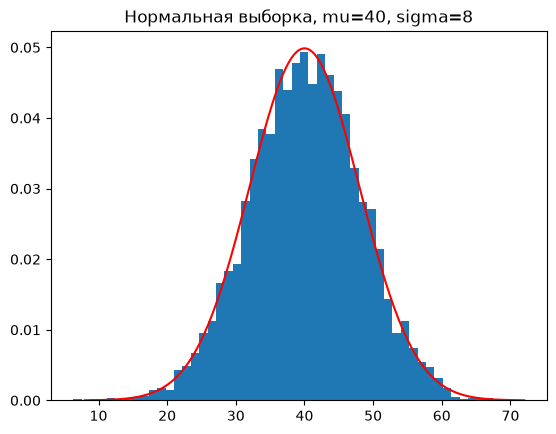

In [25]:
mu, sigma = 40, 8
sample = np.random.normal(mu, sigma, size=5000)

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 200)

plt.hist(sample, bins=50, density=True)
plt.plot(x, stats.norm.pdf(x, mu, sigma), color='red')
plt.title('Нормальная выборка, mu=40, sigma=8')
plt.show()

Сравниваю среднее и std выборки с тем, что задавал:

In [26]:
print('среднее выборки:', sample.mean())
print('std выборки:', sample.std())

среднее выборки: 40.12428789685144
std выборки: 8.02578229278286


### Задание 2.2. Биномиальная выборка

Генерирую 5000 значений биномиального распределения, с параметрами n =1000 , p=0,04

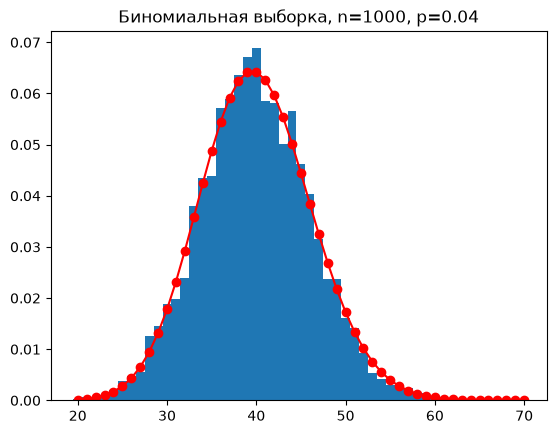

In [10]:
n, p = 1000, 0.04
sample = np.random.binomial(n, p, size=5000)

k = np.arange(sample.min(), sample.max() +1)
plt.hist(sample, bins=k - 0.5, density=True)
plt.plot(k,stats.binom.pmf(k, n, p), 'o-', color='red')
plt.title('Биномиальная выборка, n=1000, p=0.04')
plt.show()

In [11]:
print('среднее: теория', n*p, ' выборка', sample.mean())
print('std: теория', np.sqrt(n*p*(1-p)), ' выборка', sample.std())

среднее: теория 40.0  выборка 39.9366
std: теория 6.196773353931867  выборка 6.187033250274319


### Задание 2.3. ЦПТ на экспоненциальном распределении

Генерирую выборку из 500 значений экспоненциального распределения и считаю её
среднее

In [13]:
one = np.random.exponential(scale=1500, size=500)
print('среднее одной выборки:', one.mean())

среднее одной выборки: 1486.7406287491126


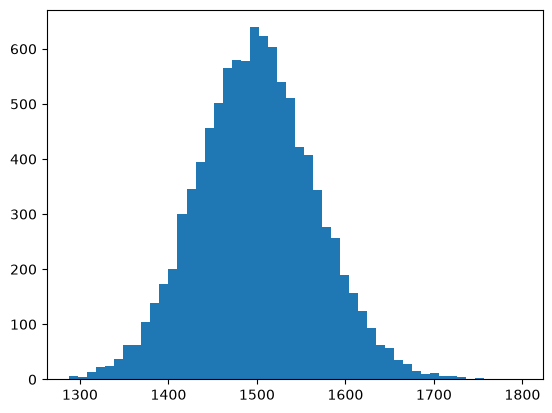

In [14]:
means = []
for i in range(10000):
    s = np.random.exponential(scale=1500, size=500)
    means.append(s.mean())

plt.hist(means, bins=50)
plt.show()

Видно, что гистограмма средних получилась симметричной и похожей на нормальное распределение. В данном случае мы видим как работает центральная предельная теорема: у экспоненциального распределения конечная дисперсия, поэтому среднее по очень большой выборке распределено примерно нормально

# 3. Мини-кейс про кнопку

### Задание 3.1. Посчитать по формуле

Для расчета буду использовать такую формулу:
$SE = \sqrt{\dfrac{p(1-p)}{n}}$

In [16]:
n = 5000
p_old = 155 / n
p_new = 170 / n

se_old = np.sqrt(p_old * (1 - p_old) / n)
se_new = np.sqrt(p_new * (1 - p_new) / n)

print('Старая кнопка:', se_old * 100, 'п.п.')
print('Новая кнопка:', se_new * 100, 'п.п.')

Старая кнопка: 0.24510813939973516 п.п.
Новая кнопка: 0.2562967030611202 п.п.


Получилось, что ошибка в обеих группах примерно 0,25 п.п., а разница у нас 0,3 п.п. То есть разница почти такая же, как ошибка.

Предварительно можно сказать, что конверсия и так может случайно гулять на 0,25 п.п., поэтому разница 0,3 п.п. вполне может быть просто случайностью. Сказать, что кнопка помогла, по этим данным нельзя

### Задание 3.2. Проверить симуляцией

Если мы предполагаем, что кнопка ни на что не влияет и конверсия в обеих группах одинаковая, то можно взять общую конверсию по двум группам: (155 + 170) / 10000 = 3,25%

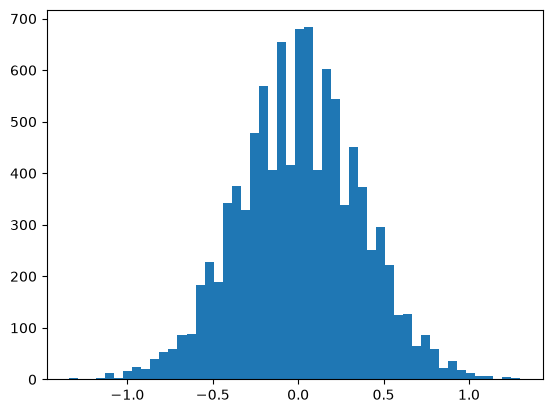

In [17]:
p = (155 + 170) / 10000

old = np.random.binomial(n, p, size=10000)
new = np.random.binomial(n, p, size=10000)

diff = (new - old) / n * 100

plt.hist(diff, bins=50)
plt.show()

In [18]:
print('доля случаев с разницей 0,3 п.п. или больше:', np.mean(new - old >= 15))

доля случаев с разницей 0,3 п.п. или больше: 0.2163


Ответ: это шум, так как по результатам вышло около 22%, то есть в каждом пятом случае разница 0,3 п.п. и больше получается сама по себе, хотя кнопка ни на что не влияет

### Задание 3.3. Выбросы во времени сессий

Правилом трёх сигм:

In [20]:
x = np.array([3, 4, 4, 5, 5, 6, 6, 7, 8, 52])

# правило трёх сигм
upper_three_sigma = x.mean() + 3 * x.std(ddof=1)
print('граница трёх сигм:', upper_three_sigma)
print('выбросы:', x[x > upper_three_sigma])

граница трёх сигм: 54.49719092257398
выбросы: []


Выбросы по перцентилям:

In [21]:
p25, p75 = np.percentile(x, [25, 75])
upper_pct = p75 + 1.5 * (p75 - p25)
print('граница по перцентилям:', upper_pct)
print('выбросы:', x[x > upper_pct])

граница по перцентилям: 10.5
выбросы: [52]


Лучше сработали перцентили. В трёх сигмах 52 мин сама участвует в расчёте и сильно раздувает std, поэтому граница уезжает дальше выброса. Перцентилям важен только порядок значений, поэтому выброс их почти не сдвигает.